# 01 — Business & Data Understanding
**Ferngill & Co. | LUBS5308M practice assessment | CRISP-DM phases 1–2**

This notebook (a) frames the business problem and (b) audits and explores the raw customer file.
It **does not change the data** — all treatments happen in `02_data_preparation.ipynb`.
Every issue found here is written to `outputs/tables/01_data_quality_log.csv` so it can be traced into the report.

| Output | Location |
|---|---|
| Data-quality log | `outputs/tables/01_data_quality_log.csv` |
| High-value vs rest profile | `outputs/tables/01_profile_high_vs_rest.csv` |
| Figures | `outputs/figures/01_*.png` |

## 1. Business Understanding (CRISP-DM phase 1)

| Element | Ferngill & Co. |
|---|---|
| **Business problem** | Campaigns treat all customers the same; personalised marketing is needed to spend effort efficiently. |
| **Decision owner** | Marketing director |
| **Business question** | *What distinguishes our most valuable customers, and how should marketing act on it?* |
| **Analytics question** | Which customer characteristics are associated with being in the high-value group (12-month spend)? |
| **Target** | `customer_value_12m` → converted to a *high-value* flag (definition tested below: top 20%) |
| **Success criterion** | A small number of **actionable** levers (things marketing can influence — subscription, email, channel, discounting, product range) with a clear, sized relationship to value. |
| **Constraint** | 250 customers, one snapshot (cross-sectional) → we can show *association*, not prove *causation*. |

Note on variables: `total_orders` and `average_order_value` are the *arithmetic components* of spend
(value ≈ orders × AOV). They describe value rather than explain it, so they are treated as **outcome descriptors, not drivers** — tested in §5.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- locate project root (works whether run from /notebooks or project root) ---
ROOT = Path.cwd()
while not (ROOT / "dataset").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "ferngill_customers.csv"
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "outputs" / "tables";  TAB.mkdir(parents=True, exist_ok=True)

# --- consistent, colour-blind-validated chart style ---
HIGH, REST, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e8e7e3",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: D:\Buss_ana


## 2. Data Understanding — first look

In [2]:
df = pd.read_csv(RAW)
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
                      "missing": df.isna().sum(), "unique": df.nunique()}))

Rows: 250  |  Columns: 13


,customer_id,age,region,acquisition_channel,tenure_months,total_orders,average_order_value,distinct_product_types,discount_sensitivity,email_engagement,satisfaction_rating,subscription_status,customer_value_12m
0,FG0001,32,Midlands,Marketplace,6,13,24.00,4,0.413,0.0,4.7,no,242.68
1,FG0002,33,Scotland & Wales,Instagram,48,26,56.96,8,0.164,70.2,4.8,yes,1833.39
2,FG0003,53,North,Google,3,5,31.35,3,0.051,33.1,4.5,no,169.39
3,FG0004,37,Scotland & Wales,Google,38,3,53.40,2,0.018,14.6,5.0,no,157.58
4,FG0005,36,Scotland & Wales,Google,16,7,19.94,4,0.214,50.6,5.0,no,114.05


,dtype,non_null,missing,unique
customer_id,object,250,0,250
age,int64,250,0,54
region,object,250,0,5
acquisition_channel,object,250,0,4
tenure_months,int64,250,0,58
total_orders,int64,250,0,29
average_order_value,float64,250,0,243
distinct_product_types,int64,250,0,10
discount_sensitivity,float64,250,0,181
email_engagement,float64,244,6,211


In [3]:
display(df.describe().T.round(2))
for c in ["region", "acquisition_channel", "subscription_status"]:
    print(f"\n{c}:\n{df[c].value_counts().to_string()}")
print("\nDuplicate customer_id:", df.customer_id.duplicated().sum(),
      "| Fully duplicated rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
age,250.0,39.58,13.01,18.00,29.00,38.00,48.00,80.00
tenure_months,250.0,24.83,14.70,1.00,14.00,23.00,36.00,71.00
total_orders,250.0,11.02,7.02,1.00,5.00,10.00,16.00,29.00
average_order_value,250.0,32.65,16.38,5.00,19.96,28.94,42.74,94.99
distinct_product_types,250.0,4.50,2.16,1.00,3.00,4.00,6.00,12.00
discount_sensitivity,250.0,0.16,0.12,0.00,0.07,0.13,0.24,0.57
email_engagement,244.0,53.08,23.68,0.00,33.25,51.40,72.70,100.00
satisfaction_rating,242.0,4.16,0.74,1.70,3.72,4.40,4.70,5.00
customer_value_12m,250.0,353.47,308.89,4.44,151.11,228.91,448.74,1833.39



region:
region
Scotland & Wales    67
North               57
South West          46
South East          43
Midlands            37

acquisition_channel:
acquisition_channel
Instagram      79
Google         76
Marketplace    59
Referral       36

subscription_status:
subscription_status
no     159
yes     91

Duplicate customer_id: 0 | Fully duplicated rows: 0


## 3. Data-quality audit
We check each column against the **documented domain in the brief**, then look for values that are *legal but suspicious*.

In [4]:
dq = []   # data-quality log: one row per issue
def log(issue, column, n, evidence, proposed):
    dq.append(dict(issue=issue, column=column, n_rows=int(n), evidence=evidence, proposed_treatment=proposed))

# 3.1 Validity vs documented domains
rules = {
    "age": (18, 100), "tenure_months": (0, None), "total_orders": (0, None),
    "average_order_value": (0, None), "distinct_product_types": (1, None),
    "discount_sensitivity": (0, 1), "email_engagement": (0, 100),
    "satisfaction_rating": (1, 5), "customer_value_12m": (0, None),
}
rows = []
for col, (lo, hi) in rules.items():
    s = df[col].dropna()
    bad = ((s < lo) if lo is not None else False) | ((s > hi) if hi is not None else False)
    rows.append(dict(column=col, min=s.min(), max=s.max(), domain=f"[{lo}, {hi if hi is not None else '∞'}]",
                     out_of_domain=int(np.sum(bad))))
display(pd.DataFrame(rows))

,column,min,max,domain,out_of_domain
0,age,18.00,80.000,"[18, 100]",0
1,tenure_months,1.00,71.000,"[0, ∞]",0
2,total_orders,1.00,29.000,"[0, ∞]",0
3,average_order_value,5.00,94.990,"[0, ∞]",0
4,distinct_product_types,1.00,12.000,"[1, ∞]",0
5,discount_sensitivity,0.00,0.566,"[0, 1]",0
6,email_engagement,0.00,100.000,"[0, 100]",0
7,satisfaction_rating,1.70,5.000,"[1, 5]",0
8,customer_value_12m,4.44,1833.390,"[0, ∞]",0


### 3.1 Missing values — how many, and *who* is missing?

In [5]:
miss = df.isna().sum(); miss = miss[miss > 0]
display(pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(1)}))

for col in miss.index:
    m = df[col].isna()
    sub_rate_missing = (df.loc[m, "subscription_status"] == "yes").mean()
    sub_rate_obs = (df.loc[~m, "subscription_status"] == "yes").mean()
    # Fisher exact test: is missingness related to subscription?
    tab = pd.crosstab(m, df.subscription_status == "yes")
    _, p_fisher = stats.fisher_exact(tab)
    # Mann–Whitney: does customer value differ for missing vs observed rows?
    _, p_mw = stats.mannwhitneyu(df.loc[m, "customer_value_12m"], df.loc[~m, "customer_value_12m"])
    print(f"\n{col}: {m.sum()} missing")
    print(f"  subscriber share  missing={sub_rate_missing:.0%}  vs observed={sub_rate_obs:.0%}  (Fisher p={p_fisher:.3f})")
    print(f"  median value      missing=£{df.loc[m,'customer_value_12m'].median():.0f}  vs observed=£{df.loc[~m,'customer_value_12m'].median():.0f}  (Mann-Whitney p={p_mw:.3f})")
    display(df.loc[m, ["customer_id", "subscription_status", "acquisition_channel", "customer_value_12m"]])

,missing,pct
email_engagement,6,2.4
satisfaction_rating,8,3.2



email_engagement: 6 missing
  subscriber share  missing=50%  vs observed=36%  (Fisher p=0.671)
  median value      missing=£353  vs observed=£223  (Mann-Whitney p=0.341)


,customer_id,subscription_status,acquisition_channel,customer_value_12m
25,FG0026,no,Instagram,261.25
64,FG0065,yes,Google,907.00
123,FG0124,no,Instagram,50.30
154,FG0155,yes,Google,753.40
156,FG0157,no,Marketplace,267.00
199,FG0200,yes,Google,439.04



satisfaction_rating: 8 missing
  subscriber share  missing=75%  vs observed=35%  (Fisher p=0.029)
  median value      missing=£443  vs observed=£223  (Mann-Whitney p=0.203)


,customer_id,subscription_status,acquisition_channel,customer_value_12m
62,FG0063,no,Marketplace,119.00
92,FG0093,yes,Instagram,738.50
116,FG0117,yes,Google,443.54
122,FG0123,yes,Referral,724.49
185,FG0186,yes,Instagram,420.89
198,FG0199,no,Google,67.17
200,FG0201,yes,Instagram,441.98
242,FG0243,yes,Google,687.99


In [6]:
log("Missing values", "email_engagement", df.email_engagement.isna().sum(),
    "6/250 (2.4%); 3 of 6 are subscribers vs 36% overall",
    "Impute median within subscription group + missing flag")
log("Missing values (not at random)", "satisfaction_rating", df.satisfaction_rating.isna().sum(),
    "8/250 (3.2%); 6 of 8 are subscribers, skewed to higher value",
    "Impute median within subscription group + missing flag; do not drop rows")

### 3.2 Suspicious-but-legal values

In [7]:
checks = {
    "average_order_value == £5.00 (possible floor/default)": df.average_order_value.eq(5.0),
    "distinct_product_types == 12 (others ≤ 9)": df.distinct_product_types.gt(9),
    "email_engagement at bounds (0 or 100)": df.email_engagement.isin([0, 100]),
    "discount_sensitivity == 0 exactly": df.discount_sensitivity.eq(0),
    "age ≥ 75": df.age.ge(75),
}
for k, m in checks.items():
    print(f"{k:55s} n={m.sum():3d}  ids={df.loc[m,'customer_id'].tolist()}")

# robust outlier screen (IQR rule) on numeric columns
num = df.select_dtypes("number").columns
q1, q3 = df[num].quantile(.25), df[num].quantile(.75); iqr = q3 - q1
out = ((df[num] < q1 - 1.5*iqr) | (df[num] > q3 + 1.5*iqr)).sum()
print("\nIQR outliers per column:\n", out[out > 0].to_string())

average_order_value == £5.00 (possible floor/default)   n=  2  ids=['FG0053', 'FG0246']
distinct_product_types == 12 (others ≤ 9)               n=  1  ids=['FG0205']
email_engagement at bounds (0 or 100)                   n=  3  ids=['FG0001', 'FG0032', 'FG0209']
discount_sensitivity == 0 exactly                       n= 12  ids=['FG0010', 'FG0028', 'FG0038', 'FG0048', 'FG0069', 'FG0125', 'FG0151', 'FG0203', 'FG0206', 'FG0213', 'FG0230', 'FG0232']
age ≥ 75                                                n=  2  ids=['FG0006', 'FG0171']

IQR outliers per column:
 age                        1
tenure_months              1
average_order_value        3
distinct_product_types     1
discount_sensitivity       3
satisfaction_rating        4
customer_value_12m        19


In [8]:
log("Suspicious value", "average_order_value", df.average_order_value.eq(5).sum(),
    "Exactly £5.00 for 2 customers - looks like a floor/default", "Keep, flag; check sensitivity")
log("Outlier", "distinct_product_types", df.distinct_product_types.gt(9).sum(),
    "One customer = 12 types; all others ≤ 9", "Cap at 9 (winsorise) + flag")
log("High-value outliers", "customer_value_12m", (df.customer_value_12m > df.customer_value_12m.quantile(.75) + 1.5*(df.customer_value_12m.quantile(.75)-df.customer_value_12m.quantile(.25))).sum(),
    "Right-skewed spend; IQR outliers are the customers we care about", "Keep - genuine, they ARE the target group")

### 3.3 Internal consistency
Two checks the brief does not hint at but a client would expect:
1. Is `customer_value_12m` consistent with `total_orders × average_order_value`?
2. Does a **12-month** spend figure make sense for customers with **< 12 months** tenure?

value / (orders × AOV):
count    250.00
mean       1.03
std        0.18
min        0.75
25%        0.89
50%        1.02
75%        1.17
max        1.74
Correlation(value, orders×AOV) = 0.97


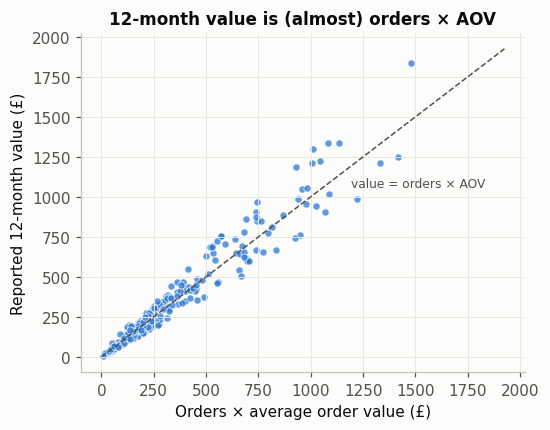

In [9]:
implied = df.total_orders * df.average_order_value
ratio = df.customer_value_12m / implied
print("value / (orders × AOV):"); print(ratio.describe().round(2).to_string())
print("Correlation(value, orders×AOV) =", round(np.corrcoef(df.customer_value_12m, implied)[0,1], 3))

fig, ax = plt.subplots(figsize=(5.2, 4))
ax.scatter(implied, df.customer_value_12m, s=22, color=HIGH, alpha=.75, edgecolor="#fcfcfb", linewidth=.6)
lim = max(implied.max(), df.customer_value_12m.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--"); ax.text(lim*.62, lim*.55, "value = orders × AOV", color=MUTED, fontsize=8)
ax.set(xlabel="Orders × average order value (£)", ylabel="Reported 12-month value (£)",
       title="12-month value is (almost) orders × AOV")
save(fig, "01_value_vs_orders_x_aov.png"); plt.show()

In [10]:
short = df.tenure_months < 12
print(f"Customers with tenure < 12 months: {short.sum()} ({short.mean():.0%}) -> their '12-month' value covers only part of a year")
fast = short & (df.total_orders > df.tenure_months * 2)
print(f"...of which > 2 orders per month of tenure (implausible for loose-leaf tea): {fast.sum()}")
display(df.loc[fast, ["customer_id", "tenure_months", "total_orders", "customer_value_12m"]].sort_values("tenure_months"))

log("Definition / leakage", "total_orders, average_order_value", len(df),
    f"value ≈ orders × AOV (r={np.corrcoef(df.customer_value_12m, implied)[0,1]:.2f}); ratio {ratio.min():.2f}-{ratio.max():.2f}",
    "Exclude from driver model (circular); use only to describe segments")
log("Partial observation window", "tenure_months", short.sum(),
    "Tenure < 12m, so 12-month value is not a full year", "Flag new customers; sensitivity check excluding them")
log("Logical inconsistency", "tenure_months vs total_orders", fast.sum(),
    "Tenure < 12m but > 2 orders per month of tenure", "Flag; keep (cannot verify which field is wrong); sensitivity check")

Customers with tenure < 12 months: 51 (20%) -> their '12-month' value covers only part of a year
...of which > 2 orders per month of tenure (implausible for loose-leaf tea): 16


,customer_id,tenure_months,total_orders,customer_value_12m
17,FG0018,1,7,156.29
18,FG0019,1,8,175.30
76,FG0077,1,3,213.83
100,FG0101,1,9,150.19
191,FG0192,1,6,160.44
211,FG0212,1,6,49.30
147,FG0148,1,13,186.58
111,FG0112,1,3,200.52
212,FG0213,1,4,449.11
229,FG0230,1,3,330.29


## 4. Exploring the target: how concentrated is value?

Skewness = 1.65 | mean £353 vs median £229
Top-20% threshold = £600 | top 20% of customers generate 49.7% of 12-month revenue
Top 10%: threshold £781, revenue share 30.3%
Top 25%: threshold £449, revenue share 57.2%


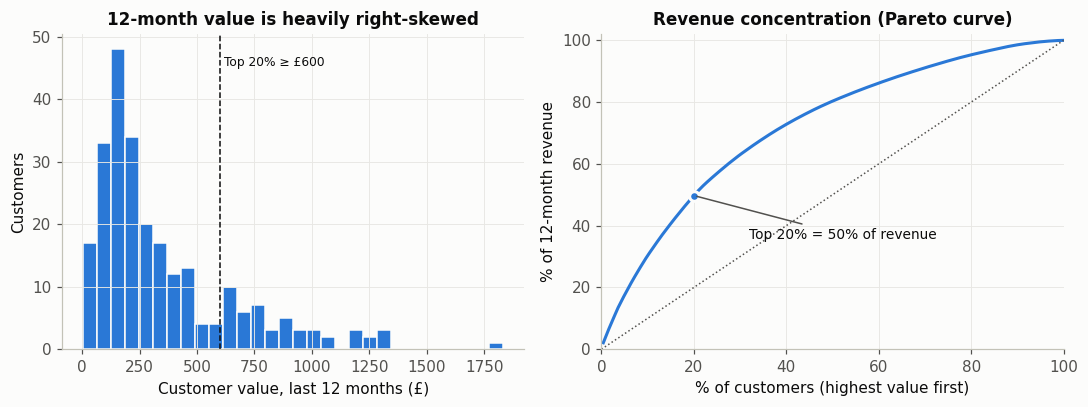

High-value customers: 50


In [11]:
v = df.customer_value_12m.sort_values(ascending=False).reset_index(drop=True)
cum_rev = v.cumsum() / v.sum(); cum_cust = (np.arange(1, len(v)+1)) / len(v)
cut80 = df.customer_value_12m.quantile(0.80)
share_top20 = v[v >= cut80].sum() / v.sum()
print(f"Skewness = {df.customer_value_12m.skew():.2f} | mean £{df.customer_value_12m.mean():.0f} vs median £{df.customer_value_12m.median():.0f}")
print(f"Top-20% threshold = £{cut80:.0f} | top 20% of customers generate {share_top20:.1%} of 12-month revenue")
for q in [.10, .25]:
    c = df.customer_value_12m.quantile(1-q); print(f"Top {q:.0%}: threshold £{c:.0f}, revenue share {v[v>=c].sum()/v.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.hist(df.customer_value_12m, bins=30, color=HIGH, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(cut80, color=INK, lw=1, ls="--"); ax.text(cut80*1.03, ax.get_ylim()[1]*.9, f"Top 20% ≥ £{cut80:.0f}", fontsize=8)
ax.set(title="12-month value is heavily right-skewed", xlabel="Customer value, last 12 months (£)", ylabel="Customers")
ax = axes[1]
ax.plot(cum_cust*100, cum_rev*100, color=HIGH, lw=2); ax.plot([0,100],[0,100], color=MUTED, lw=1, ls=":")
ax.scatter([20], [share_top20*100], s=40, color=HIGH, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"Top 20% = {share_top20:.0%} of revenue", (20, share_top20*100), xytext=(32, share_top20*100-14),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set(title="Revenue concentration (Pareto curve)", xlabel="% of customers (highest value first)", ylabel="% of 12-month revenue",
       xlim=(0,100), ylim=(0,102))
fig.tight_layout(); save(fig, "01_value_distribution_pareto.png"); plt.show()

df["high_value"] = (df.customer_value_12m >= cut80).astype(int)   # exploratory only - not saved
print("High-value customers:", df.high_value.sum())

## 5. What differs between high-value customers and the rest?
Spearman correlation is used (not Pearson) because value is skewed. Variables are tagged as **driver** (something marketing can observe/influence)
or **component** (part of the definition of value).

,spearman_rho,role
discount_sensitivity,-0.18,driver
satisfaction_rating,0.24,driver
age,0.24,driver
average_order_value,0.36,component
distinct_product_types,0.39,driver
email_engagement,0.58,driver
tenure_months,0.58,driver
total_orders,0.80,component


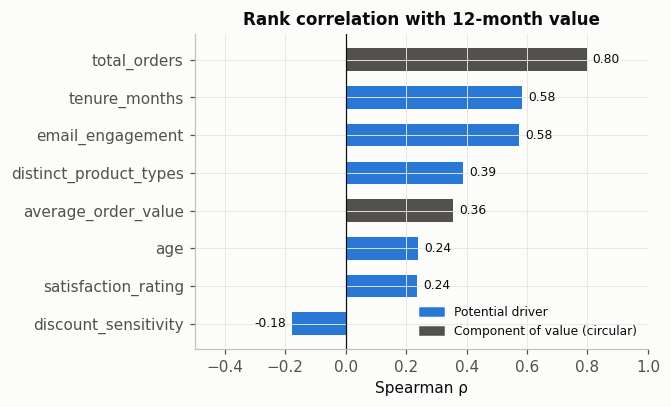

In [12]:
num_cols = ["age", "tenure_months", "distinct_product_types", "discount_sensitivity",
            "email_engagement", "satisfaction_rating", "total_orders", "average_order_value"]
rho = df[num_cols + ["customer_value_12m"]].corr(method="spearman")["customer_value_12m"].drop("customer_value_12m").sort_values()
role = {c: ("component" if c in ["total_orders", "average_order_value"] else "driver") for c in num_cols}
display(pd.DataFrame({"spearman_rho": rho.round(2), "role": rho.index.map(role)}))

fig, ax = plt.subplots(figsize=(6.2, 3.8))
colors = [MUTED if role[c] == "component" else HIGH for c in rho.index]
ax.barh(rho.index, rho.values, color=colors, height=.6)
ax.axvline(0, color=INK, lw=.8)
for i, (c, r) in enumerate(rho.items()):
    ax.text(r + (.02 if r >= 0 else -.02), i, f"{r:.2f}", va="center", ha="left" if r >= 0 else "right", fontsize=8, color=INK)
ax.set(title="Rank correlation with 12-month value", xlabel="Spearman ρ", xlim=(-.5, 1))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=HIGH, label="Potential driver"), Patch(color=MUTED, label="Component of value (circular)")],
          loc="lower right", frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "01_spearman_with_value.png"); plt.show()

In [13]:
# Numeric profile: medians, effect size, Mann-Whitney test
prof = []
for c in num_cols:
    a, b = df.loc[df.high_value==1, c].dropna(), df.loc[df.high_value==0, c].dropna()
    _, p = stats.mannwhitneyu(a, b)
    prof.append(dict(variable=c, role=role[c], high_value_median=a.median(), rest_median=b.median(),
                     ratio=round(a.median()/b.median(), 2) if b.median() else np.nan, mann_whitney_p=p))
prof = pd.DataFrame(prof)
# Categorical profile: share of each group
cat_rows = []
for c in ["subscription_status", "acquisition_channel", "region"]:
    for lvl in sorted(df[c].unique()):
        cat_rows.append(dict(variable=f"{c} = {lvl}", role="driver",
                             high_value_median=(df.loc[df.high_value==1, c]==lvl).mean(),
                             rest_median=(df.loc[df.high_value==0, c]==lvl).mean()))
cat = pd.DataFrame(cat_rows); cat["ratio"] = (cat.high_value_median / cat.rest_median).round(2)
cat = cat.rename(columns={"high_value_median": "high_value_share", "rest_median": "rest_share"})
display(prof.round(3)); display(cat.round(2))
prof.round(3).to_csv(TAB / "01_profile_high_vs_rest.csv", index=False)
cat.round(3).to_csv(TAB / "01_profile_high_vs_rest_categorical.csv", index=False)

,variable,role,high_value_median,rest_median,ratio,mann_whitney_p
0,age,driver,43.000,37.000,1.16,0.021
1,tenure_months,driver,39.000,20.000,1.95,0.000
2,distinct_product_types,driver,6.000,4.000,1.50,0.000
3,discount_sensitivity,driver,0.116,0.152,0.76,0.077
4,email_engagement,driver,77.200,44.150,1.75,0.000
5,satisfaction_rating,driver,4.500,4.300,1.05,0.002
6,total_orders,component,21.000,8.000,2.62,0.000
7,average_order_value,component,40.715,26.140,1.56,0.000


,variable,role,high_value_share,rest_share,ratio
0,subscription_status = no,driver,0.10,0.77,0.13
1,subscription_status = yes,driver,0.90,0.23,3.91
2,acquisition_channel = Google,driver,0.50,0.26,1.96
3,acquisition_channel = Instagram,driver,0.36,0.30,1.18
4,acquisition_channel = Marketplace,driver,0.00,0.30,0.00
5,acquisition_channel = Referral,driver,0.14,0.14,0.97
6,region = Midlands,driver,0.10,0.16,0.62
7,region = North,driver,0.24,0.22,1.07
8,region = Scotland & Wales,driver,0.16,0.30,0.54
9,region = South East,driver,0.18,0.17,1.06


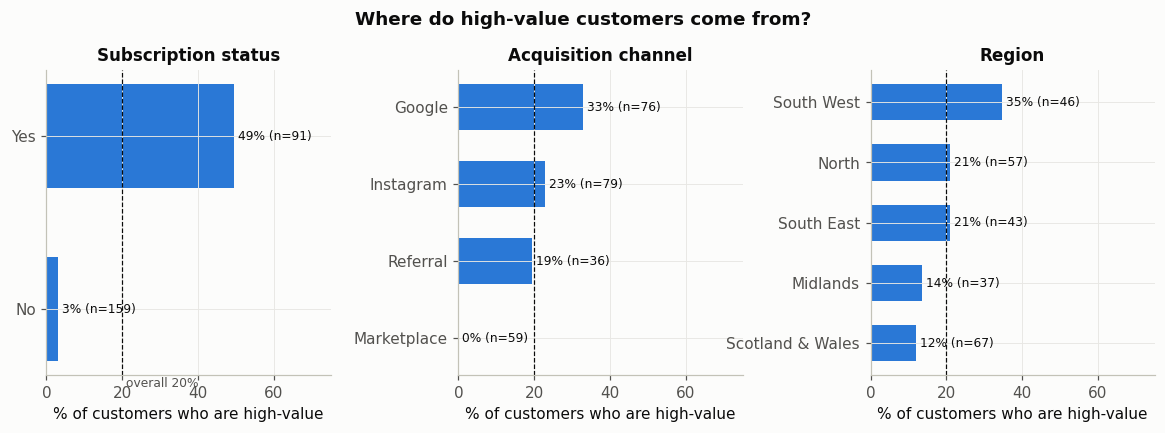

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(wspace=.45))
for ax, c in zip(axes, ["subscription_status", "acquisition_channel", "region"]):
    r = df.groupby(c).high_value.agg(["mean", "size"]).sort_values("mean")
    ax.barh(np.arange(len(r)), r["mean"]*100, color=HIGH, height=.6)
    ax.set_yticks(np.arange(len(r)), [s.capitalize() if s in ("yes", "no") else s for s in r.index])
    ax.axvline(df.high_value.mean()*100, color=INK, lw=.8, ls="--")
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m*100 + 1, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
    ax.set(title=c.replace("_", " ").capitalize(), xlabel="% of customers who are high-value", xlim=(0, 75))
axes[0].text(df.high_value.mean()*100 + 1, -0.45, "overall 20%", fontsize=8, color=MUTED)
fig.suptitle("Where do high-value customers come from?", fontweight="bold", y=1.03)
save(fig, "01_high_value_rate_by_category.png"); plt.show()

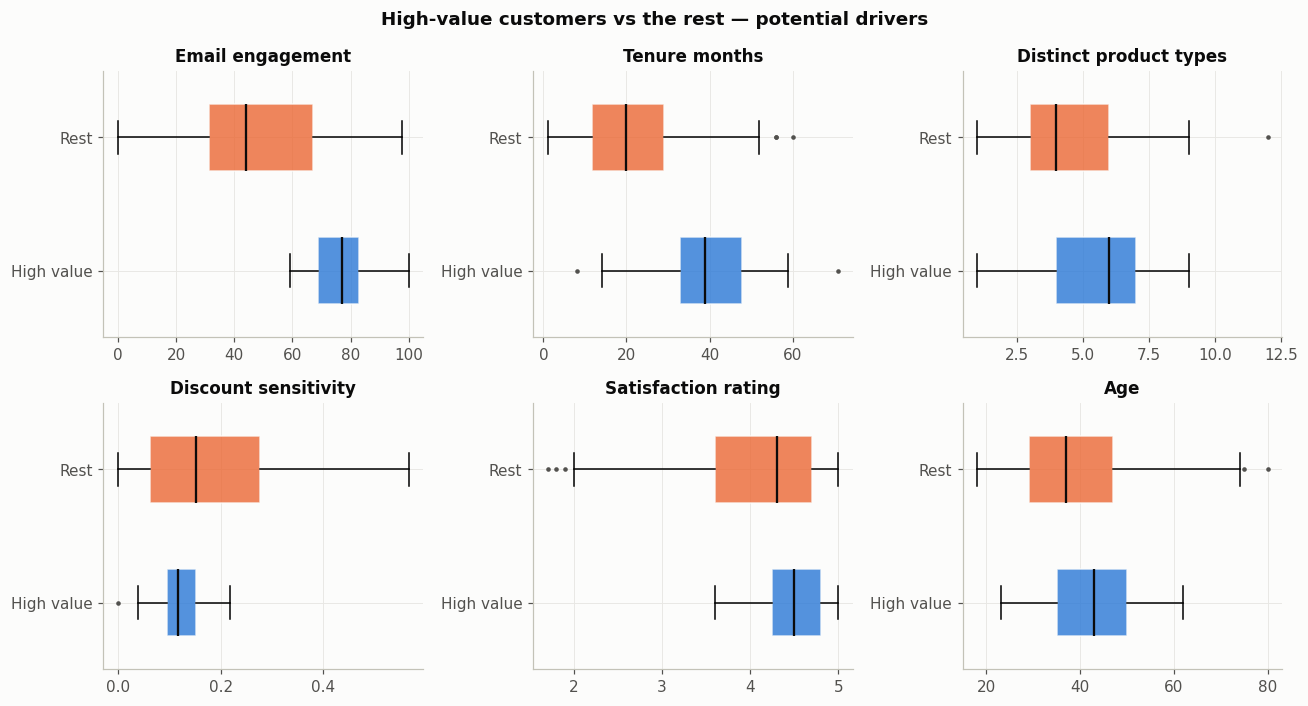

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, c in zip(axes.ravel(), ["email_engagement", "tenure_months", "distinct_product_types",
                                "discount_sensitivity", "satisfaction_rating", "age"]):
    data = [df.loc[df.high_value==1, c].dropna(), df.loc[df.high_value==0, c].dropna()]
    bp = ax.boxplot(data, vert=False, widths=.5, patch_artist=True, tick_labels=["High value", "Rest"],
                    medianprops=dict(color=INK, lw=1.5), flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none"))
    for patch, col in zip(bp["boxes"], [HIGH, REST]):
        patch.set_facecolor(col); patch.set_alpha(.8); patch.set_edgecolor("#fcfcfb")
    ax.set_title(c.replace("_", " ").capitalize())
fig.suptitle("High-value customers vs the rest — potential drivers", fontweight="bold")
fig.tight_layout(); save(fig, "01_boxplots_high_vs_rest.png"); plt.show()

## 6. Relationships *between* the drivers (needed before modelling)
If drivers move together (e.g. subscribers are also the most email-engaged), a simple comparison overstates each one.
This is why Step 3 uses a **multivariable** model rather than a series of one-at-a-time comparisons.

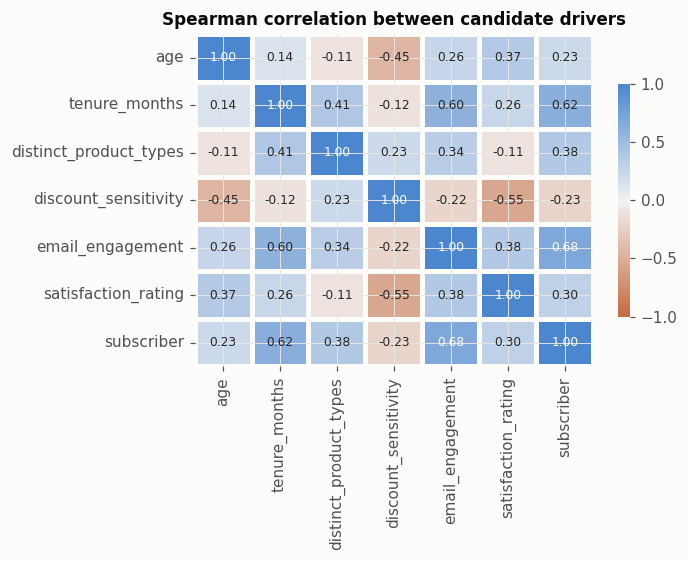

Pairs with |rho| ≥ 0.5:
 tenure_months         email_engagement       0.60
                      subscriber             0.62
discount_sensitivity  satisfaction_rating   -0.55
email_engagement      subscriber             0.68


In [16]:
X = df[num_cols].copy(); X["subscriber"] = (df.subscription_status == "yes").astype(int)
corr = X.drop(columns=["total_orders", "average_order_value"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(28, 250, s=75, l=55, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor="#fcfcfb", cbar_kws=dict(shrink=.7), ax=ax, annot_kws=dict(size=8))
ax.set_title("Spearman correlation between candidate drivers")
fig.tight_layout(); save(fig, "01_driver_correlation_heatmap.png"); plt.show()
strong = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pairs with |rho| ≥ 0.5:\n", strong[strong.abs() >= .5].round(2).to_string())

## 7. Data-quality log (input to Step 2)

In [17]:
dq_log = pd.DataFrame(dq)
dq_log.to_csv(TAB / "01_data_quality_log.csv", index=False)
display(dq_log)

,issue,column,n_rows,evidence,proposed_treatment
0,Missing values,email_engagement,6,6/250 (2.4%); 3 of 6 are subscribers vs 36% ov...,Impute median within subscription group + miss...
1,Missing values (not at random),satisfaction_rating,8,"8/250 (3.2%); 6 of 8 are subscribers, skewed t...",Impute median within subscription group + miss...
2,Suspicious value,average_order_value,2,Exactly £5.00 for 2 customers - looks like a f...,"Keep, flag; check sensitivity"
3,Outlier,distinct_product_types,1,One customer = 12 types; all others ≤ 9,Cap at 9 (winsorise) + flag
4,High-value outliers,customer_value_12m,19,Right-skewed spend; IQR outliers are the custo...,"Keep - genuine, they ARE the target group"
5,Definition / leakage,"total_orders, average_order_value",250,value ≈ orders × AOV (r=0.97); ratio 0.75-1.74,Exclude from driver model (circular); use only...
6,Partial observation window,tenure_months,51,"Tenure < 12m, so 12-month value is not a full ...",Flag new customers; sensitivity check excludin...
7,Logical inconsistency,tenure_months vs total_orders,16,Tenure < 12m but > 2 orders per month of tenure,Flag; keep (cannot verify which field is wrong...


## 8. Summary for discussion
**Value is concentrated.** The top 20% of customers (≥ £600) generate **49.7%** of 12-month revenue (skew = 1.65). This justifies a
*high-value* flag at the top 20% and supports the case for personalised (not uniform) marketing.

**What distinguishes high-value customers (one variable at a time):**
| Signal | High-value | Rest |
|---|---|---|
| Active subscription | **90%** | 23% |
| Acquired via Marketplace | **0%** | 30% |
| Acquired via Google | 50% | 26% |
| Median email engagement | 77 | 44 |
| Median tenure (months) | 39 | 20 |
| Median distinct tea types | 6 | 4 |
| Median discount sensitivity | 0.12 | 0.15 (weak, p = 0.08) |

**Caution:** subscription, email engagement and tenure are strongly inter-correlated (ρ = 0.60–0.68), so these effects overlap.
Step 3 must use a multivariable model to separate them.

**Data-quality issues → Step 2:**
1. Missing `satisfaction_rating` (8) is **not random**: 75% of missing rows are subscribers vs 35% overall (Fisher p = 0.029).
   Overall-mean imputation would bias against the high-value group → impute within subscription group + missing flag.
2. Missing `email_engagement` (6): no significant pattern (p = 0.67) → same treatment for consistency.
3. `customer_value_12m` ≈ orders × AOV (r = 0.97) → orders and AOV are **excluded as drivers** (circular).
4. 51 customers (20%) have tenure < 12 months, so their 12-month value is a part-year figure; 16 show > 2 orders per month of tenure → flag + sensitivity check.
5. Minor: one product-type outlier (12), two AOVs of exactly £5.00, 12 customers with exactly 0 discount sensitivity → flag/cap, low impact.
6. No duplicates, no out-of-domain values, clean categories.